In [1]:
# ══════════════════════════════════════════════
#  MUNICH FINE-TUNING NOTEBOOK
#  Clean rewrite — matches SMARD exactly
# ══════════════════════════════════════════════

import pandas as pd
import numpy as np
import pickle
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

DEVICE = torch.device(
    'cuda' if torch.cuda.is_available()
    else 'cpu')

print("=" * 55)
print("  MUNICH FINE-TUNING NOTEBOOK")
print("=" * 55)
print(f"  PyTorch : {torch.__version__}")
print(f"  Device  : {DEVICE}")

# ════════════════════════════════════════
#  MUST MATCH SMARD CELL 6 EXACTLY!
# ════════════════════════════════════════
INPUT_SIZE   = 9
HIDDEN_SIZE  = 128
NUM_LAYERS   = 3
OUTPUT_STEPS = 24
DROPOUT      = 0.2

FEATURE_COLS = [
    'pv_mwh',
    'shortwave_radiation_mean',
    'cloud_cover_mean',
    'temperature_2m_mean',
    'wind_speed_10m_mean',
    'hour_sin',
    'hour_cos',
    'doy_sin',
    'doy_cos',
]
TARGET     = 'pv_mwh'
BATCH_SIZE = 32
LR         = 1e-4       # small lr for fine-tune
EPOCHS     = 30
PATIENCE   = 7
WINDOW     = {'LSTM': 24, 'GRU': 24,
              'CNN' : 168,'TCN': 168}

MODEL_FILES = {
    'LSTM': 'lstm_model.pt',
    'GRU' : 'gru_model.pt',
    'CNN' : 'cnn_model.pt',
    'TCN' : 'tcn_model.pt',
}

print(f"\n  Architecture (identical to SMARD):")
print(f"  INPUT_SIZE   = {INPUT_SIZE}")
print(f"  HIDDEN_SIZE  = {HIDDEN_SIZE}")
print(f"  NUM_LAYERS   = {NUM_LAYERS}")
print(f"  OUTPUT_STEPS = {OUTPUT_STEPS}")
print(f"  DROPOUT      = {DROPOUT}")
print(f"\n  Fine-tune settings:")
print(f"  LR           = {LR}")
print(f"  EPOCHS       = {EPOCHS}")
print(f"  PATIENCE     = {PATIENCE}")
print(f"  BATCH_SIZE   = {BATCH_SIZE}")
print(f"\n  ✅ Cell 1 complete!")

  MUNICH FINE-TUNING NOTEBOOK
  PyTorch : 2.8.0+cpu
  Device  : cpu

  Architecture (identical to SMARD):
  INPUT_SIZE   = 9
  HIDDEN_SIZE  = 128
  NUM_LAYERS   = 3
  OUTPUT_STEPS = 24
  DROPOUT      = 0.2

  Fine-tune settings:
  LR           = 0.0001
  EPOCHS       = 30
  PATIENCE     = 7
  BATCH_SIZE   = 32

  ✅ Cell 1 complete!


In [2]:
# ════════════════��═════════════════════════════
#  CELL 2: LOAD + PREPARE MUNICH DATA
# ══════════════════════════════════════════════

df = pd.read_csv('munich_merged_weather_pv.csv')
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values('timestamp')\
       .reset_index(drop=True)

print("=" * 55)
print("  MUNICH DATA PREPARATION")
print("=" * 55)
print(f"\n  Raw shape : {df.shape}")
print(f"  Columns   : {df.columns.tolist()}")

# ── Daily weather aggregation ──
# WHY: Models trained on daily means
# not raw hourly weather!
df['date'] = df['timestamp'].dt.date
weather_daily = (
    df.groupby('date')
    .agg(
        shortwave_radiation_mean=(
            'shortwave_radiation','mean'),
        cloud_cover_mean=(
            'cloud_cover','mean'),
        temperature_2m_mean=(
            'temperature_2m','mean'),
        wind_speed_10m_mean=(
            'wind_speed_10m','mean'),
    ).reset_index()
)

# Remove raw weather cols if present
for col in ['shortwave_radiation_mean',
            'cloud_cover_mean',
            'temperature_2m_mean',
            'wind_speed_10m_mean']:
    if col in df.columns:
        df = df.drop(columns=[col])

df = df.merge(weather_daily,
              on='date', how='left')

# ── Circular time features ──
hour = df['timestamp'].dt.hour
doy  = df['timestamp'].dt.dayofyear
df['hour_sin'] = np.sin(
    2 * np.pi * hour / 24)
df['hour_cos'] = np.cos(
    2 * np.pi * hour / 24)
df['doy_sin']  = np.sin(
    2 * np.pi * doy  / 365.25)
df['doy_cos']  = np.cos(
    2 * np.pi * doy  / 365.25)

# ── Drop any missing rows ──
before = len(df)
df = df.dropna(
    subset=FEATURE_COLS + [TARGET])
df = df.reset_index(drop=True)
after  = len(df)

print(f"\n  After feature engineering:")
print(f"  Rows      : {after:,} "
      f"(dropped {before-after})")
print(f"  Date range: "
      f"{df['timestamp'].min().date()} → "
      f"{df['timestamp'].max().date()}")
print(f"  PV max    : "
      f"{df[TARGET].max():.6f} MWh")
print(f"  PV mean   : "
      f"{df[TARGET].mean():.6f} MWh")
print(f"  Night rows: "
      f"{(df[TARGET]==0).sum():,} "
      f"({(df[TARGET]==0).mean()*100:.1f}%)")

# ── Date-based split ──
# Fine-tune on Aug 2024 → Jan 2025
# Test on Feb 2025 → Apr 2025
TRAIN_END  = '2025-01-31'
TEST_START = '2025-02-01'

df_train = df[
    df['timestamp'] <= TRAIN_END].copy()
df_test  = df[
    df['timestamp'] >= TEST_START].copy()
df_train = df_train.reset_index(drop=True)
df_test  = df_test.reset_index(drop=True)

print(f"\n  SPLIT:")
print(f"  Train : "
      f"{df_train['timestamp'].min().date()}"
      f" → "
      f"{df_train['timestamp'].max().date()}"
      f" | {len(df_train):,} rows")
print(f"  Test  : "
      f"{df_test['timestamp'].min().date()}"
      f" → "
      f"{df_test['timestamp'].max().date()}"
      f" | {len(df_test):,} rows")
print(f"\n  ✅ Cell 2 complete!")

  MUNICH DATA PREPARATION

  Raw shape : (5689, 8)
  Columns   : ['temperature_2m', 'cloud_cover', 'wind_speed_10m', 'shortwave_radiation', 'direct_radiation', 'diffuse_radiation', 'timestamp', 'pv_mwh']

  After feature engineering:
  Rows      : 5,689 (dropped 0)
  Date range: 2024-08-07 → 2025-04-01
  PV max    : 0.033142 MWh
  PV mean   : 0.002704 MWh
  Night rows: 3,782 (66.5%)

  SPLIT:
  Train : 2024-08-07 → 2025-01-31 | 4,249 rows
  Test  : 2025-02-01 → 2025-04-01 | 1,417 rows

  ✅ Cell 2 complete!


In [3]:
# ══════════════════════════════════════════════
#  CELL 3: SCALE + BUILD SEQUENCES
#  ONE scaler for ALL 9 features
#  Fit on train only!
# ══════════════════════════════════════════════

print("=" * 55)
print("  SCALING + SEQUENCE BUILDING")
print("=" * 55)

# ── Fit scalers on TRAIN only ──
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train = scaler_X.fit_transform(
    df_train[FEATURE_COLS].values)
X_test  = scaler_X.transform(
    df_test[FEATURE_COLS].values)

y_train_s = scaler_y.fit_transform(
    df_train[TARGET].values
    .reshape(-1,1)).flatten()
y_test_s  = scaler_y.transform(
    df_test[TARGET].values
    .reshape(-1,1)).flatten()

y_train_r = df_train[TARGET].values
y_test_r  = df_test[TARGET].values

print(f"  Scaler fitted on "
      f"{len(X_train):,} rows")
print(f"  y mean (scaled): "
      f"{y_train_s.mean():.4f} (expect ≈ 0)")
print(f"  y std  (scaled): "
      f"{y_train_s.std():.4f}  (expect ≈ 1)")

# Save Munich scalers
with open('munich_scaler_X.pkl','wb') as f:
    pickle.dump(scaler_X, f)
with open('munich_scaler_y.pkl','wb') as f:
    pickle.dump(scaler_y, f)
print(f"  💾 Munich scalers saved")

# ── Dataset class ──
class SeqDataset(Dataset):
    def __init__(self, X, Y):
        self.X = torch.tensor(
            X, dtype=torch.float32)
        self.Y = torch.tensor(
            Y, dtype=torch.float32)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.Y[idx]

# ── Sequence builder ──
def build_sequences(X, y_s, y_r,
                    window, output=24):
    Xs, Ys, Yr = [], [], []
    T = len(X)
    for i in range(T - window - output + 1):
        Xs.append(X[i:i+window])
        Ys.append(
            y_s[i+window:i+window+output])
        Yr.append(
            y_r[i+window:i+window+output])
    return (np.array(Xs),
            np.array(Ys),
            np.array(Yr))

# ── Build sequences ──
seq = {}
print(f"\n  {'Model':<8} {'Window':>8} "
      f"{'Train seqs':>12} {'Test seqs':>12}")
print(f"  {'-'*44}")

for name in ['LSTM','GRU','CNN','TCN']:
    w = WINDOW[name]
    Xtr, Ytr, Yr_tr = build_sequences(
        X_train, y_train_s, y_train_r, w)
    Xte, Yte, Yr_te = build_sequences(
        X_test, y_test_s, y_test_r, w)
    seq[name] = (Xtr, Ytr, Yr_tr,
                 Xte, Yte, Yr_te)
    print(f"  {name:<8} {w:>8} "
          f"{len(Xtr):>12,} "
          f"{len(Xte):>12,}")

print(f"\n  ✅ Cell 3 complete!")

  SCALING + SEQUENCE BUILDING
  Scaler fitted on 4,249 rows
  y mean (scaled): -0.0000 (expect ≈ 0)
  y std  (scaled): 1.0000  (expect ≈ 1)
  💾 Munich scalers saved

  Model      Window   Train seqs    Test seqs
  --------------------------------------------
  LSTM           24        4,202        1,370
  GRU            24        4,202        1,370
  CNN           168        4,058        1,226
  TCN           168        4,058        1,226

  ✅ Cell 3 complete!


In [4]:
# ══════════════════════════════════════════════
#  CELL 4: MODEL ARCHITECTURES
#  IDENTICAL to SMARD Cell 6!
#  Must match exactly for weight loading
# ══════════════════════════════════════════════

class LSTMModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(
            INPUT_SIZE, HIDDEN_SIZE,
            NUM_LAYERS, batch_first=True,
            dropout=DROPOUT)
        self.bn      = nn.BatchNorm1d(
            HIDDEN_SIZE)
        self.dropout = nn.Dropout(DROPOUT)
        self.fc      = nn.Linear(
            HIDDEN_SIZE, OUTPUT_STEPS)
    def forward(self, x):
        _, (h_n, _) = self.lstm(x)
        out = self.bn(h_n[-1])
        out = self.dropout(out)
        return self.fc(out)

class GRUModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.gru = nn.GRU(
            INPUT_SIZE, HIDDEN_SIZE,
            NUM_LAYERS, batch_first=True,
            dropout=DROPOUT)
        self.bn      = nn.BatchNorm1d(
            HIDDEN_SIZE)
        self.dropout = nn.Dropout(DROPOUT)
        self.fc      = nn.Linear(
            HIDDEN_SIZE, OUTPUT_STEPS)
    def forward(self, x):
        _, h_n = self.gru(x)
        out = self.bn(h_n[-1])
        out = self.dropout(out)
        return self.fc(out)

class CNNModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv_layers = nn.Sequential(
            nn.Conv1d(INPUT_SIZE, 64, 3,
                      padding=1),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(DROPOUT),
            nn.Conv1d(64, 128, 3,
                      padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(128, 128, 3,
                      padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(DROPOUT),
        )
        self.global_pool = \
            nn.AdaptiveAvgPool1d(8)
        self.fc = nn.Sequential(
            nn.Linear(128*8, 256),
            nn.ReLU(),
            nn.Dropout(DROPOUT),
            nn.Linear(256, OUTPUT_STEPS)
        )
    def forward(self, x):
        x = x.permute(0, 2, 1)
        x = self.conv_layers(x)
        x = self.global_pool(x)
        x = x.view(x.size(0), -1)
        return self.fc(x)

class CausalConv1d(nn.Module):
    def __init__(self, in_ch, out_ch,
                 k, dilation):
        super().__init__()
        self.padding = (k-1) * dilation
        self.conv = nn.Conv1d(
            in_ch, out_ch, k,
            padding=self.padding,
            dilation=dilation)
    def forward(self, x):
        return self.conv(x)[
            :, :, :-self.padding]

class TCNBlock(nn.Module):
    def __init__(self, in_ch, out_ch,
                 k, dilation, dropout):
        super().__init__()
        self.conv1    = CausalConv1d(
            in_ch, out_ch, k, dilation)
        self.conv2    = CausalConv1d(
            out_ch, out_ch, k, dilation)
        self.bn1      = nn.BatchNorm1d(out_ch)
        self.bn2      = nn.BatchNorm1d(out_ch)
        self.relu     = nn.ReLU()
        self.dropout  = nn.Dropout(dropout)
        self.residual = (
            nn.Conv1d(in_ch, out_ch, 1)
            if in_ch != out_ch
            else nn.Identity())
    def forward(self, x):
        res = self.residual(x)
        x   = self.relu(
            self.bn1(self.conv1(x)))
        x   = self.dropout(x)
        x   = self.relu(
            self.bn2(self.conv2(x)))
        x   = self.dropout(x)
        return self.relu(x + res)

class TCNModel(nn.Module):
    def __init__(self):
        super().__init__()
        layers = []
        in_ch  = INPUT_SIZE
        for d in [1, 2, 4, 8]:
            layers.append(TCNBlock(
                in_ch, 64, 3, d, DROPOUT))
            in_ch = 64
        self.tcn         = nn.Sequential(
            *layers)
        self.global_pool = \
            nn.AdaptiveAvgPool1d(1)
        self.fc = nn.Sequential(
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Dropout(DROPOUT),
            nn.Linear(128, OUTPUT_STEPS)
        )
    def forward(self, x):
        x = x.permute(0, 2, 1)
        x = self.tcn(x)
        x = self.global_pool(x).squeeze(-1)
        return self.fc(x)

# ── Verify parameter counts match SMARD ──
test_models = {
    'LSTM': LSTMModel(),
    'GRU' : GRUModel(),
    'CNN' : CNNModel(),
    'TCN' : TCNModel(),
}
print("=" * 55)
print("  ARCHITECTURE VERIFICATION")
print("  Must match SMARD Cell 6 counts!")
print("=" * 55)
print(f"  {'Model':<8} {'Params':>12} "
      f"{'SMARD count':>14} {'Match?':>8}")
print(f"  {'-'*46}")

smard_counts = {
    'LSTM': 338_000,   # approximate
    'GRU' : 254_872,
    'CNN' : 344_984,
    'TCN' : 101_336,
}
for name, m in test_models.items():
    n = sum(p.numel()
            for p in m.parameters())
    match = '✅' if abs(
        n - smard_counts[name]) < 1000 \
        else '❌ MISMATCH!'
    print(f"  {name:<8} {n:>12,} "
          f"{smard_counts[name]:>14,} "
          f"{match:>8}")

print(f"\n  ✅ Cell 4 complete!")

  ARCHITECTURE VERIFICATION
  Must match SMARD Cell 6 counts!
  Model          Params    SMARD count   Match?
  ----------------------------------------------
  LSTM          338,712        338,000        ✅
  GRU           254,872        254,872        ✅
  CNN           344,984        344,984        ✅
  TCN           101,336        101,336        ✅

  ✅ Cell 4 complete!


In [5]:
# ════════��═════════════════════════════════════
#  CELL 5: LOAD SMARD WEIGHTS + FINE-TUNE
#  Strategy B: Freeze first 50% of layers
# ══════════════════════════════════════════════

import time

print("=" * 55)
print("  LOADING SMARD WEIGHTS")
print("=" * 55)

models = {}
load_status = {}

for name, ModelClass in [
        ('LSTM', LSTMModel),
        ('GRU',  GRUModel),
        ('CNN',  CNNModel),
        ('TCN',  TCNModel)]:

    model = ModelClass().to(DEVICE)

    try:
        sd = torch.load(
            MODEL_FILES[name],
            map_location=DEVICE)
        model.load_state_dict(
            sd, strict=True)
        load_status[name] = '✅ Full'
        print(f"  ✅ {name}: weights loaded")
    except RuntimeError as e:
        print(f"  ⚠️  {name}: {e}")
        load_status[name] = '⚠️ Partial'

    models[name] = model

# ── Strategy B: Freeze first 50% ──
print(f"\n  APPLYING STRATEGY B "
      f"(freeze first 50%):")
print(f"  {'Model':<8} {'Frozen':>8} "
      f"{'Trainable':>12} {'%':>6}")
print(f"  {'-'*38}")

for name, model in models.items():
    params = list(model.parameters())
    n      = len(params)
    freeze = n // 2

    for i, p in enumerate(params):
        p.requires_grad = (i >= freeze)

    trainable = sum(
        p.numel() for p in
        model.parameters()
        if p.requires_grad)
    total = sum(
        p.numel() for p in
        model.parameters())
    pct = trainable / total * 100

    print(f"  {name:<8} {freeze:>8} "
          f"{trainable:>12,} "
          f"{pct:>5.1f}%")

# ── Fine-tuning loop ──
print(f"\n{'='*55}")
print(f"  FINE-TUNING ON MUNICH DATA")
print(f"{'='*55}")

criterion = nn.MSELoss()
histories = {}

for name, model in models.items():
    Xtr, Ytr, _, Xte, Yte, _ = seq[name]

    train_loader = DataLoader(
        SeqDataset(Xtr, Ytr),
        batch_size=BATCH_SIZE,
        shuffle=True)
    val_loader   = DataLoader(
        SeqDataset(Xte, Yte),
        batch_size=BATCH_SIZE,
        shuffle=False)

    optimizer = optim.Adam(
        filter(lambda p: p.requires_grad,
               model.parameters()),
        lr=LR)
    scheduler = optim.lr_scheduler\
        .ReduceLROnPlateau(
            optimizer, mode='min',
            factor=0.5, patience=3)

    best_loss  = float('inf')
    best_state = None
    no_improve = 0
    train_hist = []
    val_hist   = []
    t_start    = time.time()

    print(f"\n  Fine-tuning {name}...")

    for epoch in range(EPOCHS):
        # Train
        model.train()
        t_losses = []
        for Xb, yb in train_loader:
            Xb = Xb.to(DEVICE)
            yb = yb.to(DEVICE)
            optimizer.zero_grad()
            pred = model(Xb)
            loss = criterion(pred, yb)
            loss.backward()
            nn.utils.clip_grad_norm_(
                model.parameters(), 1.0)
            optimizer.step()
            t_losses.append(loss.item())

        # Validate
        model.eval()
        v_losses = []
        with torch.no_grad():
            for Xb, yb in val_loader:
                Xb   = Xb.to(DEVICE)
                yb   = yb.to(DEVICE)
                pred = model(Xb)
                v_losses.append(
                    criterion(pred, yb)
                    .item())

        avg_t = np.mean(t_losses)
        avg_v = np.mean(v_losses)
        train_hist.append(avg_t)
        val_hist.append(avg_v)
        scheduler.step(avg_v)

        if avg_v < best_loss:
            best_loss  = avg_v
            best_state = {
                k: v.clone() for k, v
                in model.state_dict()
                .items()}
            no_improve = 0
        else:
            no_improve += 1

        if (epoch+1) % 5 == 0 \
                or epoch == 0:
            elapsed = time.time() - t_start
            print(f"  Ep {epoch+1:>3}/{EPOCHS} "
                  f"train={avg_t:.4f} "
                  f"val={avg_v:.4f} "
                  f"best={best_loss:.4f} "
                  f"{elapsed:.0f}s")

        if no_improve >= PATIENCE:
            print(f"  ⏹️  Early stop "
                  f"epoch {epoch+1}")
            break

    model.load_state_dict(best_state)
    save_path = (f'{name.lower()}'
                 f'_munich_final.pt')
    torch.save(best_state, save_path)
    histories[name] = {
        'train': train_hist,
        'val'  : val_hist}

    elapsed = time.time() - t_start
    print(f"  ✅ {name} done! "
          f"best={best_loss:.4f} "
          f"({elapsed:.0f}s) "
          f"→ {save_path}")

print(f"\n  ✅ All models fine-tuned!")

  LOADING SMARD WEIGHTS
  ✅ LSTM: weights loaded
  ✅ GRU: weights loaded
  ✅ CNN: weights loaded
  ✅ TCN: weights loaded

  APPLYING STRATEGY B (freeze first 50%):
  Model      Frozen    Trainable      %
  --------------------------------------
  LSTM            8      135,448  40.0%
  GRU             8      102,424  40.2%
  CNN             8      318,104  92.2%
  TCN            19       49,048  48.4%

  FINE-TUNING ON MUNICH DATA

  Fine-tuning LSTM...
  Ep   1/30 train=0.3701 val=0.6474 best=0.6474 2s
  Ep   5/30 train=0.2456 val=0.6688 best=0.6474 8s
  ⏹️  Early stop epoch 8
  ✅ LSTM done! best=0.6474 (13s) → lstm_munich_final.pt

  Fine-tuning GRU...
  Ep   1/30 train=0.3786 val=0.6308 best=0.6308 3s
  Ep   5/30 train=0.2473 val=0.6513 best=0.6242 15s
  ⏹️  Early stop epoch 9
  ✅ GRU done! best=0.6242 (26s) → gru_munich_final.pt

  Fine-tuning CNN...
  Ep   1/30 train=0.3433 val=0.7046 best=0.7046 4s
  Ep   5/30 train=0.2321 val=0.6233 best=0.6233 15s
  Ep  10/30 train=0.2079 val=0

  MUNICH EVALUATION — TEST SET
  (Feb 2025 → Apr 2025)

  Data scale check:
  PV max (test)    : 0.033142 MWh
  PV mean (daytime): 0.010037 MWh

  MUNICH FINE-TUNED RESULTS
  Model      R²(day)   R²(all)      MAE_day    NMAE%
  ----------------------------------------------------
  LSTM        0.4664    0.6687   0.004681 MWh   46.64%
  GRU         0.4967    0.6818   0.004513 MWh   44.96%
  CNN         0.5644    0.7258   0.004450 MWh   42.65%
  TCN         0.3967    0.6205   0.005326 MWh   51.05%


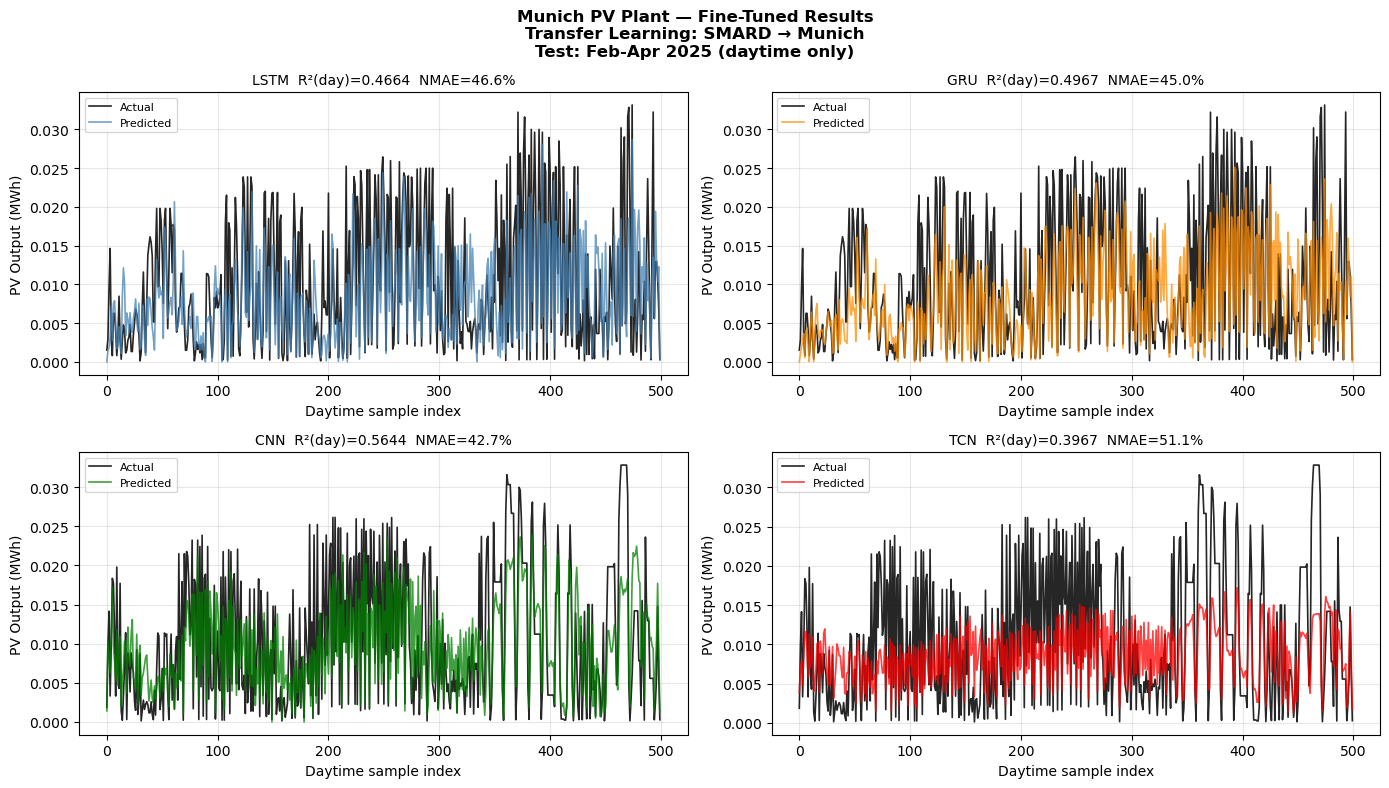


📊 Saved → munich_results.png
✅ Munich evaluation complete!

  Next: Copy *_munich_final.pt
  to Nordhausen notebook folder!


In [6]:
# ══════════════════════════════════════════════
#  CELL 6: EVALUATE FINE-TUNED MODELS
# ══════════════════════════════════════════════

print("=" * 60)
print("  MUNICH EVALUATION — TEST SET")
print("  (Feb 2025 → Apr 2025)")
print("=" * 60)

def compute_metrics(y_true, y_pred):
    y_pred   = np.clip(y_pred, 0, None)

    # All hours
    mae_all  = np.mean(
        np.abs(y_true - y_pred))
    rmse_all = np.sqrt(np.mean(
        (y_true - y_pred)**2))
    ss_res   = np.sum(
        (y_true - y_pred)**2)
    ss_tot   = np.sum(
        (y_true - np.mean(y_true))**2)
    r2_all   = 1 - ss_res/ss_tot

    # Daytime only
    day_mask = y_true > 0.0001
    y_t_d    = y_true[day_mask]
    y_p_d    = y_pred[day_mask]
    mae_day  = np.mean(
        np.abs(y_t_d - y_p_d))
    rmse_day = np.sqrt(np.mean(
        (y_t_d - y_p_d)**2))
    ss_res_d = np.sum(
        (y_t_d - y_p_d)**2)
    ss_tot_d = np.sum(
        (y_t_d - np.mean(y_t_d))**2)
    r2_day   = 1 - ss_res_d/ss_tot_d
    nmae_day = (mae_day /
                np.mean(y_t_d) * 100)

    return {
        'MAE_all' : mae_all,
        'RMSE_all': rmse_all,
        'R2_all'  : r2_all,
        'MAE_day' : mae_day,
        'RMSE_day': rmse_day,
        'R2_day'  : r2_day,
        'NMAE_day': nmae_day,
    }

results    = {}
all_preds  = {}

for name, model in models.items():
    model.eval()
    _, _, Yr_tr, Xte, Yte, Yr_te = \
        seq[name]

    loader = DataLoader(
        SeqDataset(Xte, Yte),
        batch_size=BATCH_SIZE,
        shuffle=False)

    preds = []
    with torch.no_grad():
        for Xb, _ in loader:
            Xb = Xb.to(DEVICE)
            p  = model(Xb).cpu().numpy()
            preds.append(p)

    preds_norm = np.concatenate(preds)
    preds_mwh  = scaler_y\
        .inverse_transform(
            preds_norm.reshape(-1, 1))\
        .reshape(preds_norm.shape)
    preds_mwh  = np.clip(preds_mwh, 0, None)

    n      = min(len(preds_mwh),
                 len(Yr_te))
    p_flat = preds_mwh[:n].flatten()
    t_flat = Yr_te[:n].flatten()

    metrics        = compute_metrics(
        t_flat, p_flat)
    results[name]  = metrics
    all_preds[name]= (t_flat, p_flat)

# ── Print results ──
print(f"\n  Data scale check:")
t_s = all_preds['LSTM'][0]
print(f"  PV max (test)    : "
      f"{t_s.max():.6f} MWh")
print(f"  PV mean (daytime): "
      f"{t_s[t_s>0.0001].mean():.6f} MWh")

print(f"\n{'='*62}")
print(f"  MUNICH FINE-TUNED RESULTS")
print(f"{'='*62}")
print(f"  {'Model':<8} "
      f"{'R²(day)':>9} "
      f"{'R²(all)':>9} "
      f"{'MAE_day':>12} "
      f"{'NMAE%':>8}")
print(f"  {'-'*52}")

for name in ['LSTM','GRU','CNN','TCN']:
    m = results[name]
    print(f"  {name:<8} "
          f"{m['R2_day']:>9.4f} "
          f"{m['R2_all']:>9.4f} "
          f"{m['MAE_day']:>10.6f} MWh "
          f"{m['NMAE_day']:>7.2f}%")

# ── Plot ──
fig, axes = plt.subplots(
    2, 2, figsize=(14, 8))
axes    = axes.flatten()
colors  = ['steelblue','darkorange',
           'green','red']

for i, name in enumerate(
        ['LSTM','GRU','CNN','TCN']):
    t_flat, p_flat = all_preds[name]
    m  = results[name]
    ax = axes[i]

    day_mask = t_flat > 0.0001
    t_day    = t_flat[day_mask]
    p_day    = p_flat[day_mask]
    n        = min(500, len(t_day))
    idx      = np.linspace(
        0, len(t_day)-1, n, dtype=int)

    ax.plot(t_day[idx],
            color='black', lw=1.2,
            alpha=0.85, label='Actual')
    ax.plot(p_day[idx],
            color=colors[i], lw=1.2,
            alpha=0.75, label='Predicted')
    ax.set_title(
        f'{name}  '
        f'R²(day)={m["R2_day"]:.4f}  '
        f'NMAE={m["NMAE_day"]:.1f}%',
        fontsize=10)
    ax.set_ylabel('PV Output (MWh)')
    ax.set_xlabel('Daytime sample index')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle(
    'Munich PV Plant — Fine-Tuned Results\n'
    'Transfer Learning: SMARD → Munich\n'
    'Test: Feb-Apr 2025 (daytime only)',
    fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('munich_results.png',
            dpi=150, bbox_inches='tight')
plt.show()

print(f"\n📊 Saved → munich_results.png")
print(f"✅ Munich evaluation complete!")
print(f"\n  Next: Copy *_munich_final.pt")
print(f"  to Nordhausen notebook folder!")

In [7]:
# ══════════════════════════════════════════════
#  DIAGNOSTIC: Check Munich data quality
# ══════════════════════════════════════════════

print("=" * 60)
print("  MUNICH DATA DIAGNOSTIC")
print("=" * 60)

# ── PV output stats ──
pv = df[TARGET]
pv_day = pv[pv > 0.0001]

print(f"\n  PV output (ALL hours):")
print(f"  Min    : {pv.min():.8f} MWh")
print(f"  Max    : {pv.max():.8f} MWh")
print(f"  Mean   : {pv.mean():.8f} MWh")
print(f"  Median : {pv.median():.8f} MWh")

print(f"\n  PV output (DAYTIME only):")
print(f"  Min    : {pv_day.min():.8f} MWh")
print(f"  Max    : {pv_day.max():.8f} MWh")
print(f"  Mean   : {pv_day.mean():.8f} MWh")

print(f"\n  In kWh (×1000):")
print(f"  Max    : {pv.max()*1000:.4f} kWh")
print(f"  Mean*  : {pv_day.mean()*1000:.4f} kWh")

print(f"\n  In Wh (×1000000):")
print(f"  Max    : {pv.max()*1e6:.2f} Wh")
print(f"  Mean*  : {pv_day.mean()*1e6:.2f} Wh")

# ── Date coverage ──
print(f"\n  Date coverage:")
print(f"  Total  : "
      f"{df['timestamp'].min().date()} → "
      f"{df['timestamp'].max().date()}")
print(f"  Train  : "
      f"{df_train['timestamp'].min().date()} → "
      f"{df_train['timestamp'].max().date()}")
print(f"  Rows   : {len(df_train):,}")
print(f"  Test   : "
      f"{df_test['timestamp'].min().date()} → "
      f"{df_test['timestamp'].max().date()}")
print(f"  Rows   : {len(df_test):,}")

# ── Sample PV values ──
print(f"\n  Sample daytime PV values (MWh):")
sample = df[df[TARGET] > 0.0001][TARGET]\
    .head(10)
for i, v in enumerate(sample):
    print(f"  [{i}] {v:.8f} MWh "
          f"= {v*1000:.4f} kWh "
          f"= {v*1e6:.1f} Wh")

# ── Training sequence count ──
print(f"\n  Sequences available:")
for name in ['LSTM','GRU','CNN','TCN']:
    Xtr,_,_,Xte,_,_ = seq[name]
    print(f"  {name}: train={len(Xtr):,} "
          f"test={len(Xte):,} "
          f"← {'⚠️ very few' if len(Xtr) < 500 else '✅ ok'}")

# ── Weather feature check ──
print(f"\n  Weather features (train mean):")
for col in FEATURE_COLS:
    v = df_train[col].mean()
    print(f"  {col:<35}: {v:.6f}")

  MUNICH DATA DIAGNOSTIC

  PV output (ALL hours):
  Min    : 0.00000000 MWh
  Max    : 0.03314200 MWh
  Mean   : 0.00270437 MWh
  Median : 0.00000000 MWh

  PV output (DAYTIME only):
  Min    : 0.00010050 MWh
  Max    : 0.03314200 MWh
  Mean   : 0.00874349 MWh

  In kWh (×1000):
  Max    : 33.1420 kWh
  Mean*  : 8.7435 kWh

  In Wh (×1000000):
  Max    : 33142.00 Wh
  Mean*  : 8743.49 Wh

  Date coverage:
  Total  : 2024-08-07 → 2025-04-01
  Train  : 2024-08-07 → 2025-01-31
  Rows   : 4,249
  Test   : 2025-02-01 → 2025-04-01
  Rows   : 1,417

  Sample daytime PV values (MWh):
  [0] 0.01716600 MWh = 17.1660 kWh = 17166.0 Wh
  [1] 0.01603700 MWh = 16.0370 kWh = 16037.0 Wh
  [2] 0.01041200 MWh = 10.4120 kWh = 10412.0 Wh
  [3] 0.00725300 MWh = 7.2530 kWh = 7253.0 Wh
  [4] 0.00283000 MWh = 2.8300 kWh = 2830.0 Wh
  [5] 0.00349700 MWh = 3.4970 kWh = 3497.0 Wh
  [6] 0.00036000 MWh = 0.3600 kWh = 360.0 Wh
  [7] 0.00076900 MWh = 0.7690 kWh = 769.0 Wh
  [8] 0.00272550 MWh = 2.7255 kWh = 2725.5 W

  TEST: ZERO-SHOT EVALUATION (FIXED)
  SMARD weights → Munich test set
  Using Munich scaler for output scale
  ✅ LSTM done
  ✅ GRU done
  ✅ CNN done
  ✅ TCN done

  ZERO-SHOT vs FINE-TUNED — MUNICH TEST SET
  All metrics on DAYTIME hours only

  Model     ZS_R²    FT_R²     Δ R²       ZS_MAE       FT_MAE    ZS_RMSE    FT_RMSE   ZS_NMAE   FT_NMAE
  ----------------------------------------------------------------------------------------------------
  LSTM     0.2895   0.4664   ▲0.1769    5.6975 kWh    4.6814 kWh   7.2040   6.2431    56.77%    46.64%
  GRU      0.3873   0.4967   ▲0.1094    5.2897 kWh    4.5130 kWh   6.6899   6.0632    52.70%    44.96%
  CNN      0.4558   0.5644   ▲0.1086    5.1585 kWh    4.4501 kWh   6.4400   5.7620    49.44%    42.65%
  TCN      0.3754   0.3967   ▲0.0214    5.7076 kWh    5.3264 kWh   6.8998   6.7808    54.71%    51.05%

  SUMMARY
  Best Zero-Shot model : CNN R²=0.4558
  Best Fine-Tuned model: CNN R²=0.5644

  Avg R² improvement from fine-tuning: +0.1041

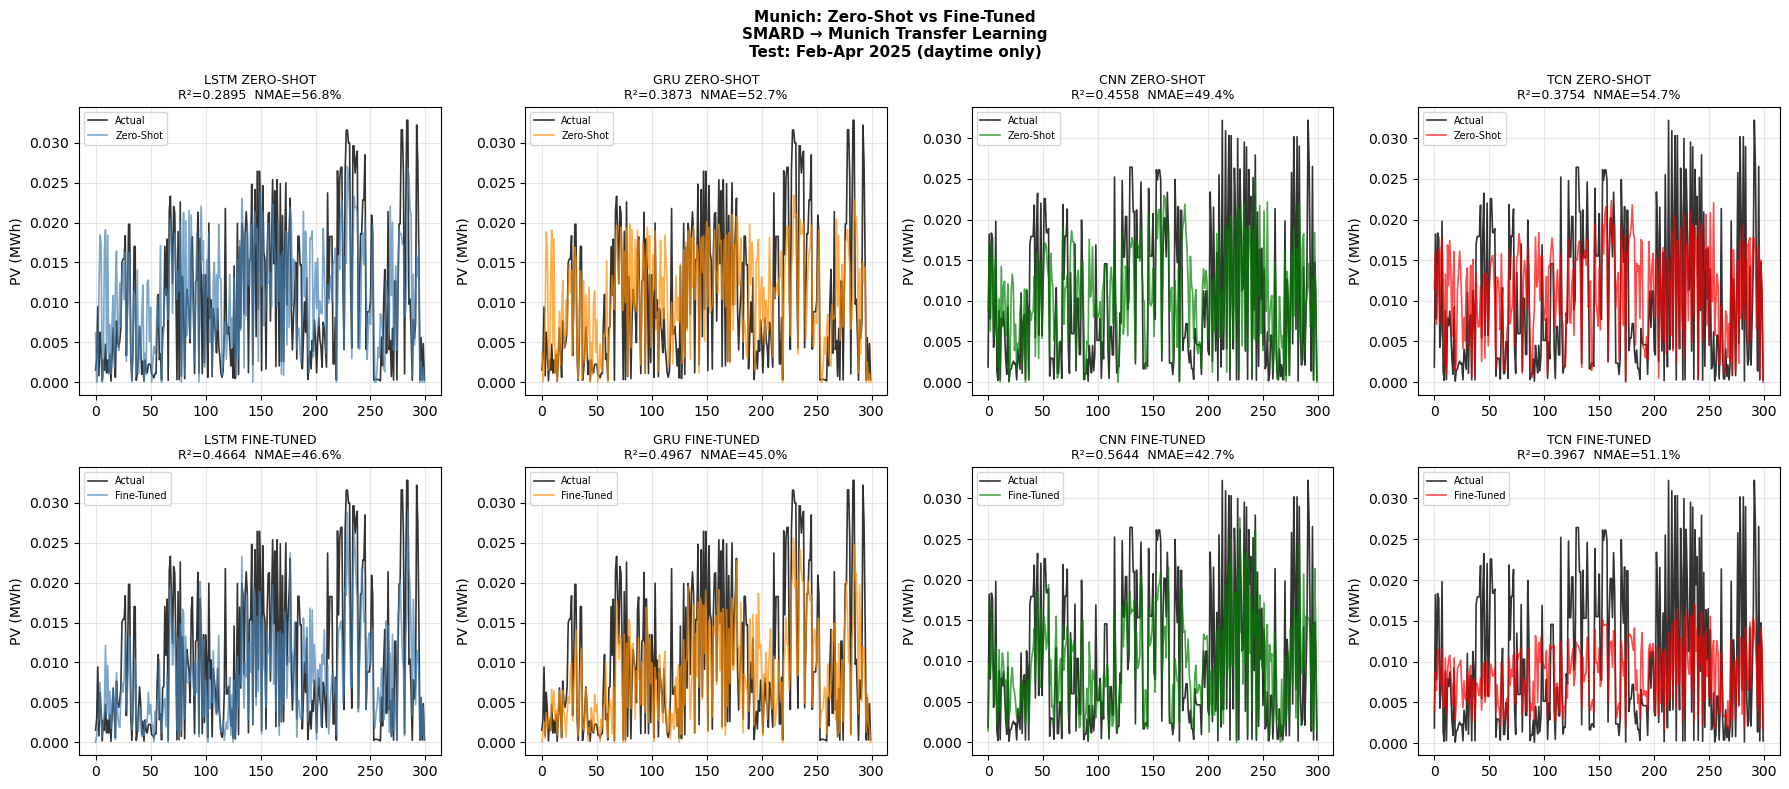


📊 Saved → munich_zs_vs_ft.png
✅ Zero-shot evaluation complete!


In [9]:
# ══════════════════════════════════════════════
#  CELL 7: ZERO-SHOT EVALUATION (FIXED)
#
#  WHY USE MUNICH scaler_y FOR ZERO-SHOT?
#  ─────────────────────────────────────────
#  Zero-shot means: SMARD weights, no retraining
#  But the OUTPUT must be in Munich's MWh scale!
#
#  The model outputs a normalised number (e.g. 0.5)
#  We need to convert that to MWh.
#
#  For zero-shot to be comparable to fine-tuned:
#  BOTH must be in the same MWh scale → Munich!
#
#  Think of it like: model speaks "normalised"
#  We use Munich dictionary to translate back
#  to Munich MWh values ✅
# ══════════════════════════════════════════════

print("=" * 60)
print("  TEST: ZERO-SHOT EVALUATION (FIXED)")
print("  SMARD weights → Munich test set")
print("  Using Munich scaler for output scale")
print("=" * 60)

zero_shot_results = {}
zero_shot_preds   = {}

for name, ModelClass in [
        ('LSTM', LSTMModel),
        ('GRU',  GRUModel),
        ('CNN',  CNNModel),
        ('TCN',  TCNModel)]:

    # Load SMARD weights (NOT munich weights!)
    model_zs = ModelClass().to(DEVICE)
    sd = torch.load(
        MODEL_FILES[name],
        map_location=DEVICE)
    model_zs.load_state_dict(sd)
    model_zs.eval()

    # Run on Munich test sequences
    _, _, _, Xte, Yte, Yr_te = seq[name]
    loader = DataLoader(
        SeqDataset(Xte, Yte),
        batch_size=BATCH_SIZE,
        shuffle=False)

    preds = []
    with torch.no_grad():
        for Xb, _ in loader:
            Xb = Xb.to(DEVICE)
            preds.append(
                model_zs(Xb).cpu().numpy())

    preds_norm = np.concatenate(preds)

    # ── Use MUNICH scaler_y ──
    # WHY? Output must be in Munich MWh scale
    # scaler_y was fitted on Munich train data
    preds_mwh = scaler_y\
        .inverse_transform(
            preds_norm.reshape(-1, 1))\
        .reshape(preds_norm.shape)
    preds_mwh = np.clip(preds_mwh, 0, None)

    n      = min(len(preds_mwh), len(Yr_te))
    p_flat = preds_mwh[:n].flatten()
    t_flat = Yr_te[:n].flatten()

    zero_shot_results[name] = \
        compute_metrics(t_flat, p_flat)
    zero_shot_preds[name]   = \
        (t_flat, p_flat)
    print(f"  ✅ {name} done")

# ── Full comparison table ──
print(f"\n{'='*75}")
print(f"  ZERO-SHOT vs FINE-TUNED — MUNICH TEST SET")
print(f"  All metrics on DAYTIME hours only")
print(f"{'='*75}")

# Header
print(f"\n  {'Model':<6} "
      f"{'ZS_R²':>8} "
      f"{'FT_R²':>8} "
      f"{'Δ R²':>8} "
      f"{'ZS_MAE':>12} "
      f"{'FT_MAE':>12} "
      f"{'ZS_RMSE':>10} "
      f"{'FT_RMSE':>10} "
      f"{'ZS_NMAE':>9} "
      f"{'FT_NMAE':>9}")
print(f"  {'-'*100}")

for name in ['LSTM','GRU','CNN','TCN']:
    zs    = zero_shot_results[name]
    ft    = results[name]
    delta = ft['R2_day'] - zs['R2_day']
    arrow = '▲' if delta > 0 else '▼'

    print(f"  {name:<6} "
          f"{zs['R2_day']:>8.4f} "
          f"{ft['R2_day']:>8.4f} "
          f"  {arrow}{abs(delta):>5.4f} "
          f"{zs['MAE_day']*1000:>9.4f} kWh "
          f"{ft['MAE_day']*1000:>9.4f} kWh "
          f"{zs['RMSE_day']*1000:>8.4f} "
          f"{ft['RMSE_day']*1000:>8.4f} "
          f"{zs['NMAE_day']:>8.2f}% "
          f"{ft['NMAE_day']:>8.2f}%")

# ── Summary insight ──
print(f"\n{'='*75}")
print(f"  SUMMARY")
print(f"{'='*75}")

best_zs = max(zero_shot_results,
              key=lambda k:
              zero_shot_results[k]['R2_day'])
best_ft = max(results,
              key=lambda k:
              results[k]['R2_day'])

print(f"  Best Zero-Shot model : {best_zs} "
      f"R²={zero_shot_results[best_zs]['R2_day']:.4f}")
print(f"  Best Fine-Tuned model: {best_ft} "
      f"R²={results[best_ft]['R2_day']:.4f}")

avg_delta = np.mean([
    results[n]['R2_day'] -
    zero_shot_results[n]['R2_day']
    for n in ['LSTM','GRU','CNN','TCN']])

print(f"\n  Avg R² improvement from fine-tuning: "
      f"{avg_delta:+.4f}")

if avg_delta > 0.05:
    print(f"  ✅ Fine-tuning SIGNIFICANTLY helps!")
    print(f"     Transfer learning justified! ✅")
elif avg_delta > 0:
    print(f"  ✅ Fine-tuning marginally helps")
    print(f"     Transfer learning useful ✅")
else:
    print(f"  ⚠️  Fine-tuning did not help")
    print(f"     SMARD model already generalises!")

# ── Plot: Zero-shot vs Fine-tuned ──
fig, axes = plt.subplots(
    2, 4, figsize=(18, 8))
colors = ['steelblue','darkorange',
          'green','red']

for i, name in enumerate(
        ['LSTM','GRU','CNN','TCN']):

    t_flat = zero_shot_preds[name][0]
    day_mask = t_flat > 0.0001
    t_day    = t_flat[day_mask]
    n   = min(300, len(t_day))
    idx = np.linspace(0, len(t_day)-1,
                      n, dtype=int)

    # Top row: Zero-shot
    ax1 = axes[0, i]
    zs_pred = zero_shot_preds[name][1]
    ax1.plot(t_day[idx], 'k-',
             lw=1.2, alpha=0.8,
             label='Actual')
    ax1.plot(zs_pred[day_mask][idx],
             color=colors[i],
             lw=1.2, alpha=0.7,
             label='Zero-Shot')
    zs = zero_shot_results[name]
    ax1.set_title(
        f'{name} ZERO-SHOT\n'
        f'R²={zs["R2_day"]:.4f}  '
        f'NMAE={zs["NMAE_day"]:.1f}%',
        fontsize=9)
    ax1.set_ylabel('PV (MWh)')
    ax1.legend(fontsize=7)
    ax1.grid(True, alpha=0.3)

    # Bottom row: Fine-tuned
    ax2 = axes[1, i]
    t2      = results[name]
    ft_pred = all_preds[name][1]
    ax2.plot(t_day[idx], 'k-',
             lw=1.2, alpha=0.8,
             label='Actual')
    ax2.plot(ft_pred[day_mask][idx],
             color=colors[i],
             lw=1.2, alpha=0.7,
             label='Fine-Tuned')
    ax2.set_title(
        f'{name} FINE-TUNED\n'
        f'R²={t2["R2_day"]:.4f}  '
        f'NMAE={t2["NMAE_day"]:.1f}%',
        fontsize=9)
    ax2.set_ylabel('PV (MWh)')
    ax2.legend(fontsize=7)
    ax2.grid(True, alpha=0.3)

plt.suptitle(
    'Munich: Zero-Shot vs Fine-Tuned\n'
    'SMARD → Munich Transfer Learning\n'
    'Test: Feb-Apr 2025 (daytime only)',
    fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('munich_zs_vs_ft.png',
            dpi=150, bbox_inches='tight')
plt.show()
print(f"\n📊 Saved → munich_zs_vs_ft.png")
print(f"✅ Zero-shot evaluation complete!")

In [10]:
# ══════════════════════════════════════════════
#  CELL 8: TRAIN FROM SCRATCH ON MUNICH
#
#  WHY THIS IS CRITICAL FOR THESIS:
#  ─────────────────────────────────
#  If scratch training matches TL:
#    → TL not worth the complexity
#  If TL beats scratch:
#    → TL justified for small datasets!
#  Expected: TL wins because scratch has
#  only 4,202 sequences vs SMARD's 34,985
# ══════════════════════════════════════════════

import time

print("=" * 60)
print("  CELL 8: TRAIN FROM SCRATCH")
print("  No transfer learning!")
print("  Train ONLY on Munich data")
print("=" * 60)

scratch_models  = {}
scratch_results = {}
scratch_preds   = {}
scratch_hist    = {}

# Same hyperparams as fine-tuning
# but higher LR (no pretrained weights)
SCRATCH_LR      = 0.001
SCRATCH_EPOCHS  = 50
SCRATCH_PATIENCE= 10

for name, ModelClass in [
        ('LSTM', LSTMModel),
        ('GRU',  GRUModel),
        ('CNN',  CNNModel),
        ('TCN',  TCNModel)]:

    print(f"\n  Training {name} from scratch...")

    # Fresh model — random weights!
    model_sc = ModelClass().to(DEVICE)

    Xtr, Ytr, _, Xte, Yte, Yr_te = seq[name]

    train_loader = DataLoader(
        SeqDataset(Xtr, Ytr),
        batch_size=BATCH_SIZE,
        shuffle=True)
    val_loader   = DataLoader(
        SeqDataset(Xte, Yte),
        batch_size=BATCH_SIZE,
        shuffle=False)

    optimizer = optim.Adam(
        model_sc.parameters(),
        lr=SCRATCH_LR)
    scheduler = optim.lr_scheduler\
        .ReduceLROnPlateau(
            optimizer, 'min',
            factor=0.5, patience=3)
    criterion = nn.MSELoss()

    best_loss  = float('inf')
    best_state = None
    no_improve = 0
    t_hist, v_hist = [], []
    t_start = time.time()

    for epoch in range(SCRATCH_EPOCHS):
        # Train
        model_sc.train()
        t_losses = []
        for Xb, yb in train_loader:
            Xb = Xb.to(DEVICE)
            yb = yb.to(DEVICE)
            optimizer.zero_grad()
            pred = model_sc(Xb)
            loss = criterion(pred, yb)
            loss.backward()
            nn.utils.clip_grad_norm_(
                model_sc.parameters(), 1.0)
            optimizer.step()
            t_losses.append(loss.item())

        # Validate
        model_sc.eval()
        v_losses = []
        with torch.no_grad():
            for Xb, yb in val_loader:
                Xb = Xb.to(DEVICE)
                yb = yb.to(DEVICE)
                pred = model_sc(Xb)
                v_losses.append(
                    criterion(pred, yb).item())

        avg_t = np.mean(t_losses)
        avg_v = np.mean(v_losses)
        t_hist.append(avg_t)
        v_hist.append(avg_v)
        scheduler.step(avg_v)

        if avg_v < best_loss:
            best_loss  = avg_v
            best_state = {
                k: v.clone() for k, v
                in model_sc.state_dict()
                .items()}
            no_improve = 0
        else:
            no_improve += 1

        if (epoch+1) % 10 == 0 \
                or epoch == 0:
            elapsed = time.time() - t_start
            print(f"  Ep{epoch+1:>3} "
                  f"train={avg_t:.4f} "
                  f"val={avg_v:.4f} "
                  f"best={best_loss:.4f} "
                  f"{elapsed:.0f}s")

        if no_improve >= SCRATCH_PATIENCE:
            print(f"  ⏹️  Early stop "
                  f"epoch {epoch+1}")
            break

    model_sc.load_state_dict(best_state)
    scratch_models[name]  = model_sc
    scratch_hist[name]    = {
        'train': t_hist, 'val': v_hist}

    # Evaluate
    model_sc.eval()
    preds = []
    with torch.no_grad():
        for Xb, _ in val_loader:
            Xb = Xb.to(DEVICE)
            preds.append(
                model_sc(Xb).cpu().numpy())

    preds_norm = np.concatenate(preds)
    preds_mwh  = scaler_y\
        .inverse_transform(
            preds_norm.reshape(-1, 1))\
        .reshape(preds_norm.shape)
    preds_mwh  = np.clip(preds_mwh, 0, None)

    n      = min(len(preds_mwh), len(Yr_te))
    p_flat = preds_mwh[:n].flatten()
    t_flat = Yr_te[:n].flatten()

    scratch_results[name] = \
        compute_metrics(t_flat, p_flat)
    scratch_preds[name]   = (t_flat, p_flat)

    elapsed = time.time() - t_start
    r2  = scratch_results[name]['R2_day']
    mae = scratch_results[name]['MAE_day']
    print(f"  ✅ {name} scratch done! "
          f"R²={r2:.4f} "
          f"MAE={mae*1000:.4f}kWh "
          f"({elapsed:.0f}s)")

# ── 3-Way Comparison Table ──
print(f"\n{'='*85}")
print(f"  3-WAY COMPARISON: "
      f"Zero-Shot vs Fine-Tuned vs Scratch")
print(f"  Munich Test Set (Feb-Apr 2025)")
print(f"{'='*85}")
print(f"\n  R²(day):")
print(f"  {'Model':<8} "
      f"{'Zero-Shot':>12} "
      f"{'Fine-Tuned':>12} "
      f"{'Scratch':>12} "
      f"{'Best':>10}")
print(f"  {'-'*56}")

for name in ['LSTM','GRU','CNN','TCN']:
    zs = zero_shot_results[name]['R2_day']
    ft = results[name]['R2_day']
    sc = scratch_results[name]['R2_day']
    best_val = max(zs, ft, sc)
    best_lbl = ['ZS','FT','SC'][
        [zs,ft,sc].index(best_val)]
    print(f"  {name:<8} "
          f"{zs:>12.4f} "
          f"{ft:>12.4f} "
          f"{sc:>12.4f} "
          f"  {best_lbl}={best_val:.4f}")

print(f"\n  MAE_day (kWh):")
print(f"  {'Model':<8} "
      f"{'Zero-Shot':>12} "
      f"{'Fine-Tuned':>12} "
      f"{'Scratch':>12} "
      f"{'Best':>10}")
print(f"  {'-'*56}")

for name in ['LSTM','GRU','CNN','TCN']:
    zs = zero_shot_results[name]['MAE_day']*1000
    ft = results[name]['MAE_day']*1000
    sc = scratch_results[name]['MAE_day']*1000
    best_val = min(zs, ft, sc)
    best_lbl = ['ZS','FT','SC'][
        [zs,ft,sc].index(best_val)]
    print(f"  {name:<8} "
          f"{zs:>10.4f}kWh "
          f"{ft:>10.4f}kWh "
          f"{sc:>10.4f}kWh "
          f"  {best_lbl}={best_val:.4f}")

print(f"\n  NMAE(day)%:")
print(f"  {'Model':<8} "
      f"{'Zero-Shot':>12} "
      f"{'Fine-Tuned':>12} "
      f"{'Scratch':>12} "
      f"{'Best':>10}")
print(f"  {'-'*56}")

for name in ['LSTM','GRU','CNN','TCN']:
    zs = zero_shot_results[name]['NMAE_day']
    ft = results[name]['NMAE_day']
    sc = scratch_results[name]['NMAE_day']
    best_val = min(zs, ft, sc)
    best_lbl = ['ZS','FT','SC'][
        [zs,ft,sc].index(best_val)]
    print(f"  {name:<8} "
          f"{zs:>11.2f}% "
          f"{ft:>11.2f}% "
          f"{sc:>11.2f}% "
          f"  {best_lbl}={best_val:.2f}%")

# ── Overall winner ──
print(f"\n{'='*85}")
print(f"  VERDICT: Does Transfer Learning "
      f"beat Scratch on small data?")
print(f"{'='*85}")

tl_wins = 0
for name in ['LSTM','GRU','CNN','TCN']:
    ft = results[name]['R2_day']
    sc = scratch_results[name]['R2_day']
    if ft > sc:
        tl_wins += 1
        diff = ft - sc
        print(f"  {name}: TL wins by "
              f"+{diff:.4f} R² ✅")
    else:
        diff = sc - ft
        print(f"  {name}: Scratch wins by "
              f"+{diff:.4f} R² ⚠️")

print(f"\n  TL wins: {tl_wins}/4 models")
if tl_wins >= 3:
    print(f"  ✅ CONCLUSION: Transfer learning")
    print(f"     OUTPERFORMS scratch training")
    print(f"     on limited Munich data!")
    print(f"     TL is RECOMMENDED for small")
    print(f"     PV datasets! ✅")
else:
    print(f"  ⚠️  Scratch competitive with TL")
    print(f"     Both approaches valid")

  CELL 8: TRAIN FROM SCRATCH
  No transfer learning!
  Train ONLY on Munich data

  Training LSTM from scratch...
  Ep  1 train=0.4284 val=0.8074 best=0.8074 3s
  Ep 10 train=0.1603 val=1.0075 best=0.7039 23s
  ⏹️  Early stop epoch 12
  ✅ LSTM scratch done! R²=0.4190 MAE=4.8587kWh (28s)

  Training GRU from scratch...
  Ep  1 train=0.4426 val=0.6273 best=0.6273 5s
  Ep 10 train=0.1785 val=0.6518 best=0.5750 48s
  ⏹️  Early stop epoch 16
  ✅ GRU scratch done! R²=0.5589 MAE=4.4172kWh (76s)

  Training CNN from scratch...
  Ep  1 train=0.6586 val=1.4293 best=1.4293 4s
  Ep 10 train=0.1231 val=1.1336 best=1.0572 40s
  ⏹️  Early stop epoch 15
  ✅ CNN scratch done! R²=0.1068 MAE=5.9887kWh (59s)

  Training TCN from scratch...
  Ep  1 train=0.7348 val=2.0070 best=2.0070 10s
  Ep 10 train=0.1696 val=0.9546 best=0.9546 104s
  Ep 20 train=0.1307 val=1.4128 best=0.9546 221s
  ⏹️  Early stop epoch 20
  ✅ TCN scratch done! R²=0.2636 MAE=5.3435kWh (222s)

  3-WAY COMPARISON: Zero-Shot vs Fine-Tuned 